## NAIVE BAYES

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("drug200.csv")

In [3]:
data.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


In [5]:
data.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [6]:
# Mengambil kolom numerikal
numerical_features = [feature for feature in data.columns if data[feature].dtypes != 'O']
print("Jumlah fitur numerik = ", 
      len(numerical_features))
print("Daftar fitur numerik = ", 
      numerical_features)
display(data[numerical_features].head())

Jumlah fitur numerik =  6
Daftar fitur numerik =  ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug']


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


In [7]:
#Mengambil kolom kategorikal
categorical_features = [feature for feature in data.columns if data[feature].dtypes == 'str']
print("Jumlah fitur kategorikal = ", 
      len(categorical_features))
print("Daftar fitur kategorikal = ", 
      categorical_features)
display(data[categorical_features].head())

Jumlah fitur kategorikal =  4
Daftar fitur kategorikal =  ['Sex', 'BP', 'Cholesterol', 'Drug']


,Sex,BP,Cholesterol,Drug
0,F,HIGH,HIGH,DrugY
1,M,LOW,HIGH,drugC
2,M,LOW,HIGH,drugC
3,F,NORMAL,HIGH,drugX
4,F,LOW,HIGH,DrugY


In [8]:
# Menampilkan data unik pada fitur kategorikal
for i in categorical_features:
    print(data[i].unique())

<StringArray>
['F', 'M']
Length: 2, dtype: str
<StringArray>
['HIGH', 'LOW', 'NORMAL']
Length: 3, dtype: str
<StringArray>
['HIGH', 'NORMAL']
Length: 2, dtype: str
<StringArray>
['DrugY', 'drugC', 'drugX', 'drugA', 'drugB']
Length: 5, dtype: str


In [9]:
# Mengubah kolom kategorikal menjadi angka untuk klasifikasi

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for feature in categorical_features:
    print(data[feature].unique())
    data[feature] = le.fit_transform(data[feature])
    print(data[feature].unique())

<StringArray>
['F', 'M']
Length: 2, dtype: str
[0 1]
<StringArray>
['HIGH', 'LOW', 'NORMAL']
Length: 3, dtype: str
[0 1 2]
<StringArray>
['HIGH', 'NORMAL']
Length: 2, dtype: str
[0 1]
<StringArray>
['DrugY', 'drugC', 'drugX', 'drugA', 'drugB']
Length: 5, dtype: str
[0 3 4 1 2]


In [10]:
data.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,0
1,47,1,1,0,13.093,3
2,47,1,1,0,10.114,3
3,28,0,2,0,7.798,4
4,61,0,1,0,18.043,0


In [11]:
# Mengambil kolom untuk fitur dan label
x = data.drop(['Drug'], axis=1)
y = data['Drug']
print(x)
print(y)

     Age  Sex  BP  Cholesterol  Na_to_K
0     23    0   0            0   25.355
1     47    1   1            0   13.093
2     47    1   1            0   10.114
3     28    0   2            0    7.798
4     61    0   1            0   18.043
..   ...  ...  ..          ...      ...
195   56    0   1            0   11.567
196   16    1   1            0   12.006
197   52    1   2            0    9.894
198   23    1   2            1   14.020
199   40    0   1            1   11.349

[200 rows x 5 columns]
0      0
1      3
2      3
3      4
4      0
      ..
195    3
196    3
197    4
198    4
199    4
Name: Drug, Length: 200, dtype: int64


In [12]:
# Membagi data menjadi data text dan data train

from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size = 0.25, random_state = 0)

In [13]:
# Melatih Model Gaussian 
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](5,)","[66.,18.,15.,13.,38.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](5,)","[0.44,0.12,0.1 ,0.09,0.25]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](5,)","[0,1,2,3,4]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,2.774e-07
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Age','Sex','BP','Cholesterol','Na_to_K']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](5, 5)","[[43.68, 0.47, 0.82, 0.45,22.57], [36.28, 0.61, 0. , 0.39,11.03], [62.67, 0.6 , 0. , 0.53,11.36], [45.38, 0.54, 1. , 0. ,10.59], [44.34, 0.55, 1.71, 0.61,10.69]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](5, 5)","[[293.31, 0.25, 0.63, 0.25, 37.09], [ 93.65, 0.24, 0. , 0.24, 4.43], [ 50.36, 0.24, 0. , 0.25, 3.08], [264.08, 0.25, 0. , 0. , 3. ], [268.12, 0.25, 0.21, 0.24, 4.28]]"


In [14]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Evaluasi Training
[[46 11  2  6  1]
 [ 0 18  0  0  0]
 [ 0  0 15  0  0]
 [ 0  0  0 13  0]
 [ 1  0  0  0 37]]
              precision    recall  f1-score   support

           0       0.98      0.70      0.81        66
           1       0.62      1.00      0.77        18
           2       0.88      1.00      0.94        15
           3       0.68      1.00      0.81        13
           4       0.97      0.97      0.97        38

    accuracy                           0.86       150
   macro avg       0.83      0.93      0.86       150
weighted avg       0.90      0.86      0.86       150



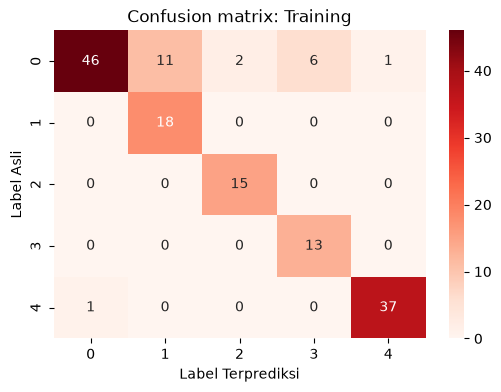

In [30]:
from sklearn.metrics import confusion_matrix, classification_report

print("Evaluasi Training")
cm_training = confusion_matrix(y_train, y_pred_train)
print(cm_training)
print(classification_report(y_train, y_pred_train))

plt.figure(figsize = (6,4))
sns.heatmap(cm_training, annot = True, fmt='d', cmap = 'Reds', xticklabels = np.unique(y), yticklabels = np.unique(y))
plt.title("Confusion matrix: Training")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show()